
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining S&P 500 Sectors.  Construct portfolios from the S&P 500 Sector ETFs and examine the results of different weighting schemes.  In particular, we can select the best performing sectors over a given period.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['etf-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='1 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,SPY,S&P 500 ETF,US Stocks:Large Cap,88.43,16.43,22.45,21.40,20.78,13.50,17.61,11.13,12.74,12.94,15.77,22.45,12.94,1.73
1,DIA,DJIA ETF,US Stocks:Large Cap,81.07,16.47,22.05,22.28,17.33,10.95,14.32,8.51,9.53,12.14,14.86,22.05,12.14,1.82
2,QQQ,Nasdaq 100 ETF,US Stocks:Growth,175.62,35.32,33.20,31.19,26.24,16.72,32.52,20.05,19.47,16.99,20.66,33.20,16.99,1.95
3,VTI,Vanguard Total Stock Market Index ETF,US Stocks:Total Stock Market,91.23,18.08,23.38,22.78,20.78,12.44,17.33,11.29,12.45,13.33,15.98,23.38,13.33,1.75
4,IWM,Russell 2000 ETF,US Stocks:Small Cap,130.94,41.13,40.23,42.92,19.10,7.00,21.68,13.17,14.08,19.75,20.64,40.23,19.75,2.04
5,MDY,S&P 400 Midcap ETF,US Stocks:Mid Cap,80.29,29.98,24.87,26.08,15.96,8.81,15.63,9.07,10.46,15.54,17.97,24.87,15.54,1.60
6,IWD,Russell 1000 Value ETF,US Stocks:Value,80.64,32.26,27.94,28.85,18.45,11.18,14.94,8.64,10.10,12.53,14.82,27.94,12.53,2.23
7,IWF,Russell 1000 Growth ETF,US Stocks:Growth,95.85,3.49,16.79,15.04,22.14,13.69,22.76,13.83,17.13,16.41,19.28,16.79,16.41,1.02
8,RSP,S&P 500 Equal Weight ETF,US Stocks:Growth,65.87,22.85,20.17,19.52,15.29,9.21,13.40,7.87,9.74,13.04,15.78,20.17,13.04,1.55
9,SPSM,S&P 600 Small Cap ETF,US Stocks:Small Cap,117.08,44.33,36.82,38.86,16.82,7.46,16.66,7.99,13.33,19.11,20.00,36.82,19.11,1.93


In [6]:
# Sector Ranking
sector_rank = bb.rank(df, rank_by='Sharpe Ratio')
sector_rank = sector_rank[sector_rank['Description'].str.contains('Sector ETF')]
#sector_rank = sector_rank.loc[(sector_rank['3 mo'] > 0) & sector_rank['1 Yr'] > 0]
#sector_rank = rank_filtered.head(10)
sector_rank

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
19,XLK,S&P500 Technology Sector ETF,US Stocks:Technology,316.77,61.40,48.47,46.03,30.42,21.85,42.34,27.20,28.52,22.32,23.64,48.47,22.32,2.17
18,XLI,S&P500 Industrials Sector ETF,US Stocks:Industrials,75.40,36.07,27.37,27.65,22.40,14.20,23.22,13.95,15.18,15.74,18.20,27.37,15.74,1.74
23,XLV,S&P500 Healthcare Sector ETF,US Stocks:Healthcare,61.30,8.27,21.85,21.84,8.47,6.92,19.78,7.60,16.00,14.09,15.01,21.85,14.09,1.55
16,XLE,S&P500 Energy Sector ETF,US Stocks:Energy,-44.63,49.87,28.86,31.34,14.83,18.91,22.99,15.28,20.36,18.98,25.79,28.86,18.98,1.52
14,XLB,S&P500 Materials Sector ETF,US Stocks:Materials,16.83,24.15,17.53,21.03,10.15,6.39,22.28,12.25,15.53,15.75,19.25,17.53,15.75,1.11
22,XLU,S&P500 Utilities Sector ETF,US Stocks:Utilities,6.50,18.68,16.55,17.98,15.13,10.67,17.63,12.29,14.99,15.03,16.52,16.55,15.03,1.10
21,XLRE,S&P500 Real Estate Sector ETF,US Stocks:Real Estate,64.53,27.25,13.42,13.51,11.14,3.40,18.86,10.91,13.22,16.59,19.27,13.42,16.59,0.81
20,XLP,S&P500 Consumer Staples Sector ETF,US Stocks:Consumer Staples,16.46,19.60,8.16,8.50,7.22,6.85,16.00,8.24,15.28,12.11,13.44,8.16,12.11,0.67
24,XLY,S&P500 Consumer Discretionary Sector ETF,US Stocks:Consumer Discretionary,52.06,-7.99,9.79,8.20,12.77,7.10,24.04,14.31,13.39,17.55,22.21,9.79,17.55,0.56
17,XLF,S&P500 Financials Sector ETF,US Stocks:Financials,61.64,-5.47,5.34,5.82,19.66,10.28,13.95,5.38,10.65,14.22,17.55,5.34,14.22,0.38


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# S&P 500 Sectors - top 4
top_sectors_portfolio = {
    'Title': 'Top S&P500 Sectors Portfolio'
}
top_sectors = list(sector_rank['Investment Option'])[:4]
top_sectors_portfolio.update(dict.fromkeys(top_sectors, 1/len(top_sectors)))

# S&P 500 Sectors - all
all_sectors_portfolio = {
    'Title': 'All S&P500 Sectors Portfolio'
}
all_sectors = list(sector_rank['Investment Option'])
all_sectors_portfolio.update(dict.fromkeys(all_sectors, 1/len(all_sectors)))

### Custom Portfolios

In [8]:
# my portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = all_sectors_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,XLK,XLI,XLV,XLE,XLB,XLU,XLRE,XLP,XLY,XLF,XLC,All S&P500 Sectors Portfolio
Annual Returns,48.47,27.37,21.85,28.86,17.53,16.55,13.42,8.16,9.79,5.34,2.64,16.05
Std Dev,22.32,15.74,14.09,18.98,15.75,15.03,16.59,12.11,17.55,14.22,13.81,9.40
Sharpe Ratio,2.17,1.74,1.55,1.52,1.11,1.10,0.81,0.67,0.56,0.38,0.19,1.71
Weight,0.04,0.08,0.11,0.07,0.09,0.09,0.10,0.11,0.08,0.11,0.09,1.00
Worst Typical Down Year,3.83,-4.11,-6.33,-9.10,-13.97,-13.51,-19.76,-16.06,-25.31,-23.10,-24.98,-2.76
Black Swan,-18.49,-19.85,-20.42,-28.08,-29.72,-28.54,-36.35,-28.17,-42.86,-37.32,-38.79,-12.16


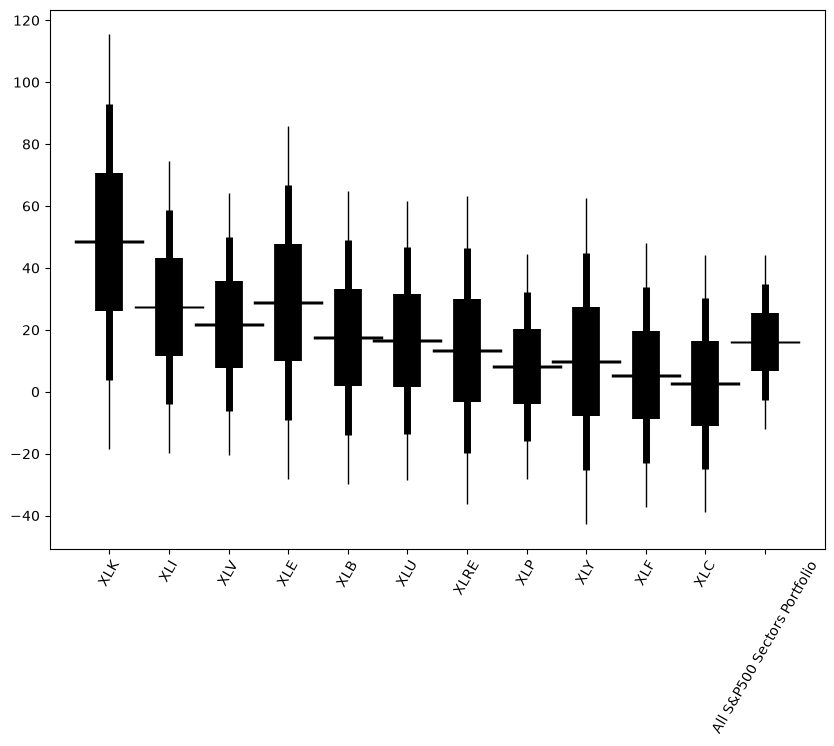

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

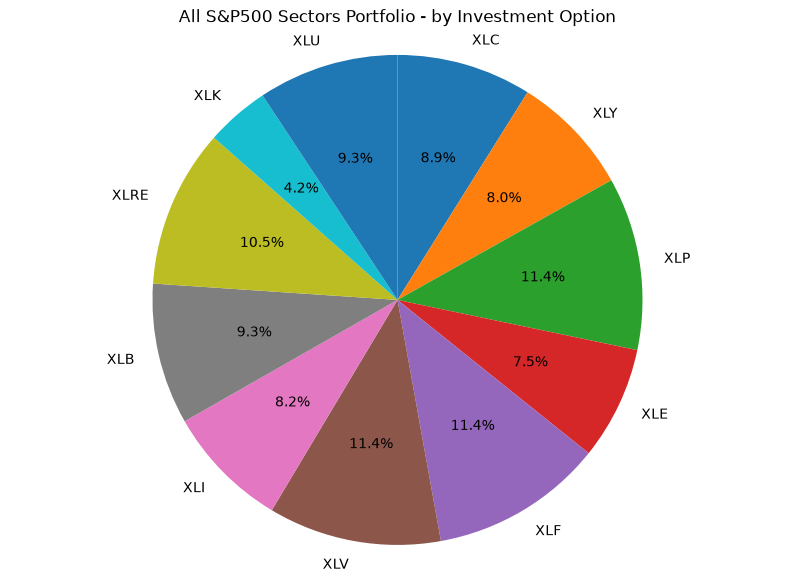

XLC    0.09
XLY    0.08
XLP    0.11
XLE    0.07
XLF    0.11
XLV    0.11
XLI    0.08
XLB    0.09
XLRE   0.10
XLK    0.04
XLU    0.09



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

All S&P500 Sectors Portfolio Weights:
    XLK                            0.0419
    XLI                            0.0818
    XLV                            0.1141
    XLE                            0.0747
    XLB                            0.0931
    XLU                            0.0928
    XLRE                           0.1046
    XLP                            0.1141
    XLY                            0.0797
    XLF                            0.1141
    XLC                            0.0891


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).